In [2]:
import earthkit.data as ekd

import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt

In [11]:
dataset = "sis-energy-global-reanalysis"
request = {
    "spatial_coverage": "global",
    "variable": ["10m_wind_speed"],
    "spatial_resolution": ["0_25_degree"],
    "temporal_resolution": ["1_hour"],
    "year": ["2025"],
    "month": [
        "01", "02", "06",
        "07"
    ],
    "version": "1_00",
    "file_format": "netcdf_4"
}

In [12]:
data = ekd.from_source("cds", dataset, request)

In [13]:
# Convert global dataset to xarray
ds = data.to_xarray()

print(ds)

<xarray.Dataset> Size: 24GB
Dimensions:    (time: 2880, latitude: 721, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 23kB 2025-01-01 ... 2025-07-31T23:00:00
  * latitude   (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude  (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
Data variables:
    ws10       (time, latitude, longitude) float64 24GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
Attributes:
    title:        10 metre wind speed - C3S Energy Lot1 file version v1.00
    institution:  Copernicus Climate Change Service, Sectoral Information Sys...
    source:       The original data sources are ECMWF ERA5 Reanalysis (availa...
    history:      ERA5; 2025-02-19 09:34 GMT via cfgrib-0.9.14.0; computed fr...
    references:   https://cds.climate.copernicus.eu/
    comment:      Produced by Inside Climate Service on behalf of C3S
    contact:      https://confluence.ecmwf.int/site/support
    conventions:  CF-1.12


In [7]:
# Create a dictionary to map dataset variables to user-friendly display names
variable_names = {
    "ws10": "10m Wind Speed", 
    "ws100": "100m Wind Speed",
}

In [8]:
def select_region(ds, lat, lon, variable):
    """
    Extract region from global dataset.
    Compute seasonal means for selected region.
    Plot seasonal average maps.

    Parameters
    ----------
        ds: Global dataset (xarray.Dataset)
        lat: Latitude bounds of region (slice)
        lon: Longitude bounds of region (slice)
        variable: Dataset variable being analysed (str)
    
    Returns
    -------
        region: Extracted regional dataset (xarray.Dataset)
        winter: Winter mean field (Jan-Feb) (xarray.DataArray)
        summer: Summer mean field (Jun-Jul) (xarray.DataArray)
    """

    # Convert longitude coordinates (from 0-360 to -180-180)
    ds = ds.assign_coords(
        longitude=((ds.longitude + 180) % 360) - 180
    ).sortby("longitude")

    # Extract region
    region = ds.sel(latitude=lat, longitude=lon)

    # Select variable
    data = region[variable]

    # Get display name for plots
    var_name = variable_names.get(variable, variable)

    # Seasonal means
    winter = (
        data
        .sel(time=data.time.dt.month.isin([1, 2]))
        .mean("time")
    )

    summer = (
        data
        .sel(time=data.time.dt.month.isin([6, 7]))
        .mean("time")
    )

    # Common colour scale
    vmin = min(float(winter.min()), float(summer.min()))
    vmax = max(float(winter.max()), float(summer.max()))

    # Plot map
    fig, axes = plt.subplots(1, 2, figsize=(14,6))

    winter.plot(ax=axes[0], cmap="viridis", vmin=vmin, vmax=vmax)
    axes[0].set_title(f"Winter Mean {var_name} (Jan-Feb 2025)")

    summer.plot(ax=axes[1], cmap="viridis", vmin=vmin, vmax=vmax)
    axes[1].set_title(f"Summer Mean {var_name} (Jun-Jul 2025)")

    plt.tight_layout()
    plt.show()

    return region, winter, summer

In [ ]:
def plot_transects(winter, summer, lat, lon, variable, loc):
    """
    Plot seasonal transects for a selected coastline or offshore region.

    Parameters
    ----------
        winter: Winter mean field (Jan-Feb) (xarray.DataArray)
        summer: Summer mean field (Jun-Jul) (xarray.DataArray)
        lat: Latitudes along which transects are extracted or range for transect bounds (list[float] or slice)
                - Use a list when plotting east-west transects and a slice when plotting north-south transects. --------
        lon: Longitude along which transects are extracted or range for transect bounds (list[float] or slice)
                - Use a slice when plotting east-west transects and a list when plotting north-south transects. --------
        variable: Dataset variable being analysed (str)
        loc: Name of specific region (and direction that coastline faces) where the transects have been extracted
    
    Returns
    -------
        Displays figure containing seasonal transect plots.
    """

    # Get display name for plots
    var_name = variable_names.get(variable, variable)

    # Plot wind speed transect
    fig, axes = plt.subplots(1, 2, figsize=(14,6), sharey=True)

    # East-west transects
    if isinstance(lat, list) and isinstance(lon, slice):

        x_label = "Longitude (°)"
        legend_title = "Latitude:"

        for ax, szn, szn_title in zip(
            axes, 
            [winter, summer], 
            ["Winter (Jan-Feb 2025)", "Summer (Jun-Jul 2025)"]
        ):
            
            for latitude in lat:
                transect = (
                    szn
                    .sel(latitude=latitude, method="nearest")
                    .sel(longitude=lon)
                )

                transect.plot(ax=ax, alpha=0.7, marker="o", linewidth=1, label=f"{latitude}°N")

            ax.set_title(szn_title)
            ax.set_xlabel(x_label)
            ax.set_ylabel("")

    # Norht-south transects
    elif isinstance(lat, slice) and isinstance(lon, list):

        x_label = "Latitude (°)"
        legend_title = "Longitude:"

        for ax, szn, szn_title in zip(
            axes, 
            [winter, summer], 
            ["Winter (Jan-Feb 2025)", "Summer (Jun-Jul 2025)"]
        ):
            
            for longitude in lon:
                transect = (
                    szn
                    .sel(longitude=longitude, method="nearest")
                    .sel(latitude=lat)
                )

                transect.plot(ax=ax, alpha=0.7, marker="o", linewidth=1, label=f"{longitude}°")

            ax.set_title(szn_title)
            ax.set_xlabel(x_label)
            ax.set_ylabel("")

    fig.suptitle(f"Mean {var_name}: {loc}")
    fig.supylabel(f"{var_name} (m/s)", x=0.08)
    axes[0].legend(title=legend_title)

    fig.subplots_adjust(wspace=0.08)

    plt.show()

    return fig

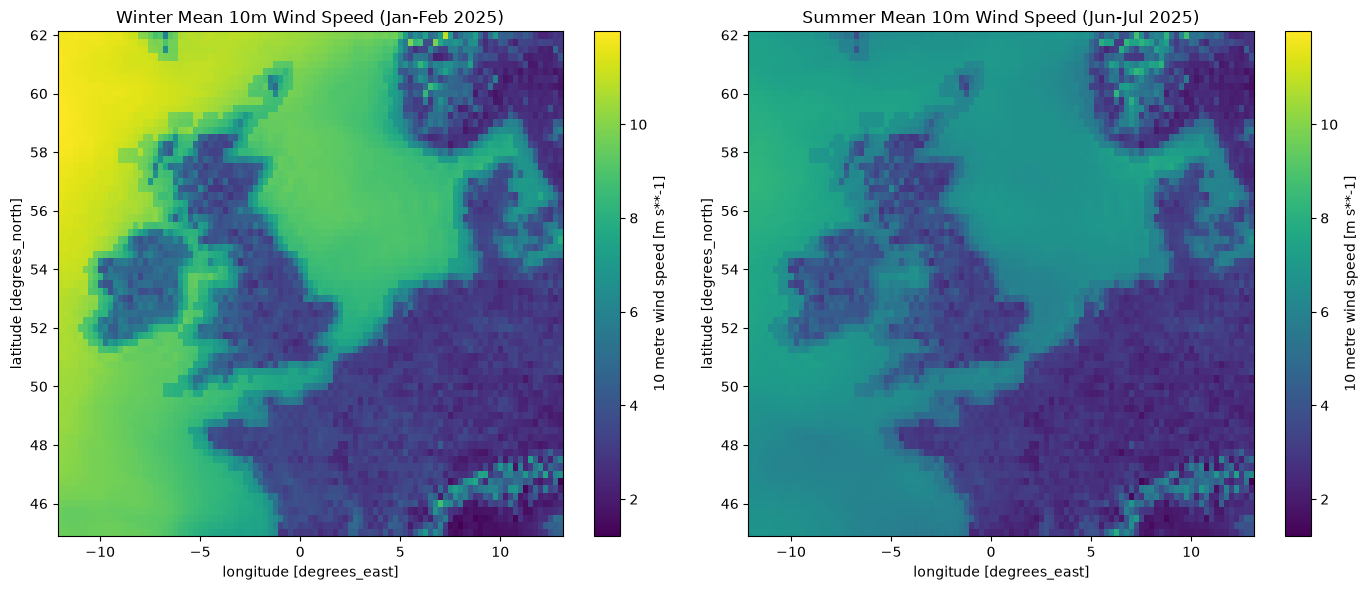

In [16]:
# ==============================
# --- North Western Europe ---
# ==============================

latitude = slice(62, 45)
longitude = slice(-12, 13)
variable = "ws10"

nw_europe, winter, summer = select_region(ds, latitude, longitude, variable)

In [ ]:
#winter.to_netcdf("GCE Indicators/Quality Assessment/Offshore Wind Assessment/Data/GCEI_WS10_nweurope_winter.nc")
#summer.to_netcdf("GCE Indicators/Quality Assessment/Offshore Wind Assessment/Data/GCEI_WS10_nweurope_summer.nc")

In [ ]:
# ----- England (East Coast) -----

location = "England (East Coast)"

latitude = [53, 53.5, 54, 54.5, 55]
longitude = slice(-2.5, 2.5)
variable = "ws100"

nw_europe_eng_E = plot_transects(winter, summer, latitude, longitude, variable, location)

In [ ]:
# ----- Scotland (East Coast) -----

location = "Scotland (East Coast)"

latitude = [56, 56.5, 57, 57.5, 58]
longitude = slice(-5.0, 0)
variable = "ws100"

nw_europe_scot_E = plot_transects(winter, summer, latitude, longitude, variable, location)

In [ ]:
# ----- Netherlands (West Coast) -----

location = "Netherlands (West Coast)"

latitude = [52, 52.5, 53]
longitude = slice(3.0, 7.0)
variable = "ws100"

nw_europe_nthlds_W = plot_transects(winter, summer, latitude, longitude, variable, location)

In [ ]:
# ----- Denmark (West Coast) -----

location = "Denmark (West Coast)"

latitude = [55, 55.5, 56, 56.5, 57]
longitude = slice(6.0, 9.0)
variable = "ws100"

nw_europe_dnmk_W = plot_transects(winter, summer, latitude, longitude, variable, location)

In [ ]:
# ----- France (West Coast) -----

location = "France (West Coast)"

latitude = [46, 46.5, 47, 47.5, 48]
longitude = slice(-7.0, 0)
variable = "ws100"

nw_europe_fr_W = plot_transects(winter, summer, latitude, longitude, variable, location)

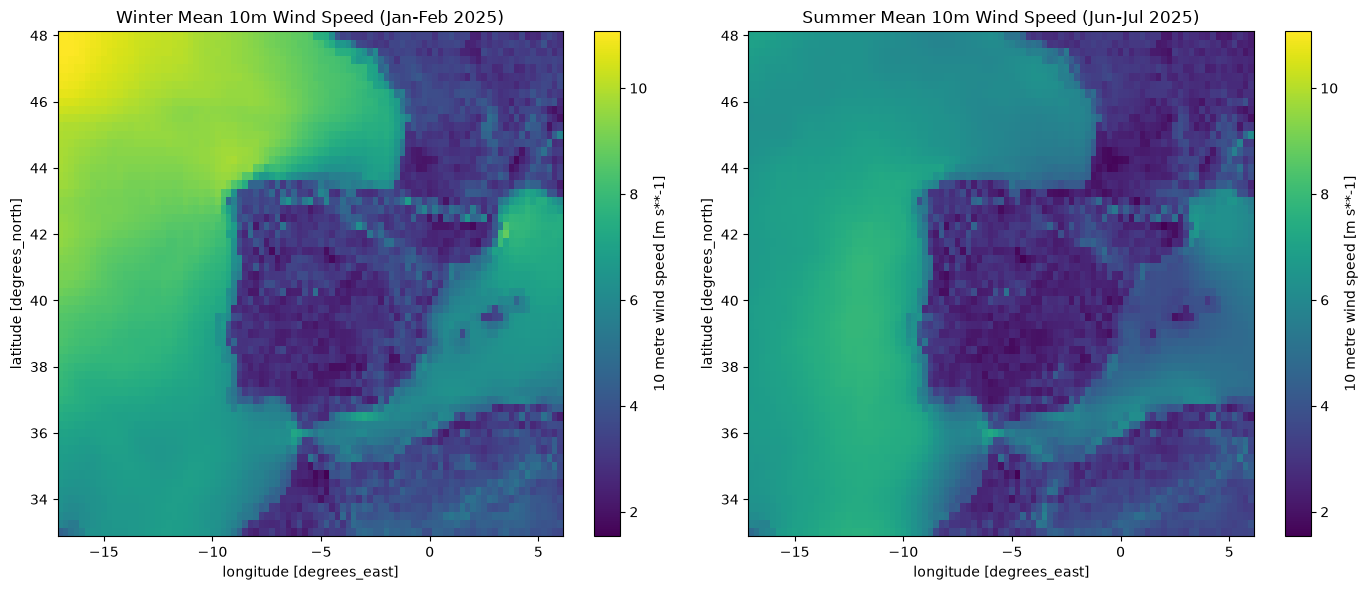

In [18]:
# ==============================
# --- Iberian Peninsula ---
# ==============================

latitude = slice(48, 33)
longitude = slice(-17, 6)
variable = "ws10"

ib_pnsla, winter, summer = select_region(ds, latitude, longitude, variable)

In [ ]:
#winter.to_netcdf("GCE Indicators/Quality Assessment/Offshore Wind Assessment/Data/GCEI_WS10_ibpnsla_winter.nc")
#summer.to_netcdf("GCE Indicators/Quality Assessment/Offshore Wind Assessment/Data/GCEI_WS10_ibpnsla_summer.nc")

In [ ]:
# ----- Southern France (West Coast) -----

location = "Southern France (West Coast)"

latitude = [44.5, 45, 45.5, 46]
longitude = slice(-7.0, 0)
variable = "ws100"

ib_pnsla_sthfr_W = plot_transects(winter, summer, latitude, longitude, variable, location)

In [ ]:
# ----- Northern Spain (North Coast) -----

location = "Spain (North Coast)"

latitude = slice(45, 42)
longitude = [-8, -7, -6, -5, -4, -3]
variable = "ws100"

ib_pnsla_sp_N = plot_transects(winter, summer, latitude, longitude, variable, location)

In [ ]:
# ----- Portugal (West Coast) -----

location = "Portugal (West Coast)"

latitude = [37.5, 38.5, 39.5, 40.5, 41.5]
longitude = slice(-12.5, -6)
variable = "ws100"

ib_pnsla_prtgl_W = plot_transects(winter, summer, latitude, longitude, variable, location)